# Temperature–mortality response and humidity modification

Native analysis for Figure 2. Relative risk is derived from each member's fitted temperature branch with the original standard age distribution and the final-day baseline.

[Original analysis notebook](https://github.com/ClimSocAna/sari-weather-mortality/blob/4402a80d3e490ad7964a3be12597043761bebda1/notebooks/02_temperature_humidity_response.ipynb).

The primary hybrid uses 50 members. Comparison ensembles use all of their available members.

In [1]:
from importlib.util import module_from_spec, spec_from_file_location
from pathlib import Path
import sys

cwd = Path.cwd()
repo = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "configs" / "training.example.yaml").is_file()
    ),
    None,
)
if repo is None:
    raise FileNotFoundError("Open the notebook from the sari-weather-mortality checkout.")

sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Load helpers from this checkout even if Jupyter cached another notebooks package.
utils_path = repo / "notebooks" / "utils.py"
spec = spec_from_file_location("sari_notebook_utils", utils_path)
notebook_utils = module_from_spec(spec)
spec.loader.exec_module(notebook_utils)

ensemble = notebook_utils.ensemble
ANALYSIS_PERIOD = notebook_utils.ANALYSIS_PERIOD
DEVICE = notebook_utils.DEVICE
checkpoint_paths = notebook_utils.checkpoint_paths

from sari_t.mean_alignment import apply_mean_alignment
from sari_t.models.interfaces import MortalityModelInputs
from sari_t.reference import build_reference_weather
from sari_t.inference import InferenceModel
from sari_t.run.checkpoint import load_checkpoint, load_run_config, restore_predictor

## Load models for inspection

Run the next cell to load member `000` for each setup into memory. Inspect `model` for the hybrid predictor or `models[setup]` for another predictor. Set `inspection_member` to another available member index to inspect its weights. The analysis cells evaluate all available members in a separate inference workspace.

In [2]:
inspection_member = 0
setups = ['default', 'no_disease', 'tas_only']
checkpoints = {setup: checkpoint_paths(setup) for setup in setups}
models = {
    setup: restore_predictor(load_checkpoint(paths[inspection_member]), device="cpu").eval()
    for setup, paths in checkpoints.items()
}
model = models["default"]
model

MortalityPredictor(
  (effect_model): ExponentialMortalityModel(
    (batch_norm): LazyBatchNorm1d(0, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv1): LazyConv1d(0, 128, kernel_size=(9,), stride=(1,))
    (fc): LinearPos(in_features=128, out_features=30, bias=True)
    (sari_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
    (covid_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
  )
)

## Evaluate the fitted response

In [3]:
temperatures = np.arange(-5, 32.5, 0.5)
std_age = torch.tensor([88569, 86870, 85970, 84670, 82171, 79272, 76073,
                        71475, 65877, 60379, 53681, 45484, 37187, 29590,
                        22092, 15195, 9097, 4398, 1500, 400, 50]).float()
std_age = torch.cat((std_age[:6].sum().reshape(1), std_age[6:-2],
                     std_age[-2:].sum().reshape(1)))[:, None]

def response(humidities):
    @torch.no_grad()
    def summarize(model, result):
        baseline = model.baseline_rate[-1] * std_age.to(model.baseline_rate.device)
        curves = {}
        for humidity in humidities:
            weather = torch.cat([
                build_reference_weather(
                    model.data.model_inputs.temperature, model.weather_variables,
                    temperature, humidity, kernel_days=model.model_config.kernel_T_days,
                )
                for temperature in temperatures
            ])
            factor = model.predictor.effect_model(
                MortalityModelInputs(weather, None, None)
            ).temperature_effect.abs()
            mortality = apply_mean_alignment(factor * baseline, model.alignment_factor)
            curves[humidity] = mortality.sum(dim=(-1, -2)).squeeze(0)
        return curves
    return summarize

summaries = {
    "default": response(range(40, 81, 10)),
    "no_disease": response([50]),
    "tas_only": response([50]),
}

estimates_by_setup = {}
for setup, summarize_member in summaries.items():
    paths = checkpoints[setup]
    inputs = load_run_config(paths[0].parents[1] / "config.yaml").data_config
    inference_model = InferenceModel.from_checkpoint(
        paths[0], data_config=inputs, period=ANALYSIS_PERIOD, device=DEVICE,
    )
    estimates_by_setup[setup] = ensemble(inference_model, paths, summarize_member, keep_members=True)
    del inference_model


setup = ["default", "no_disease"]
comparison_points = temperatures < 28.5
risk = {name: estimates_by_setup[name][50][:, comparison_points] for name in setup}
risk_1 = estimates_by_setup["tas_only"][50]
risk_2 = {humidity // 10: values
          for humidity, values in estimates_by_setup["default"].items()}

## Manuscript Figure 2: Response curves

Risk is expressed as `(RR - 1) × 100` relative to the minimum of each fitted curve. Dashed grey segments identify temperature-humidity combinations outside the observed humidity range and should not be interpreted as empirically supported exposure combinations.

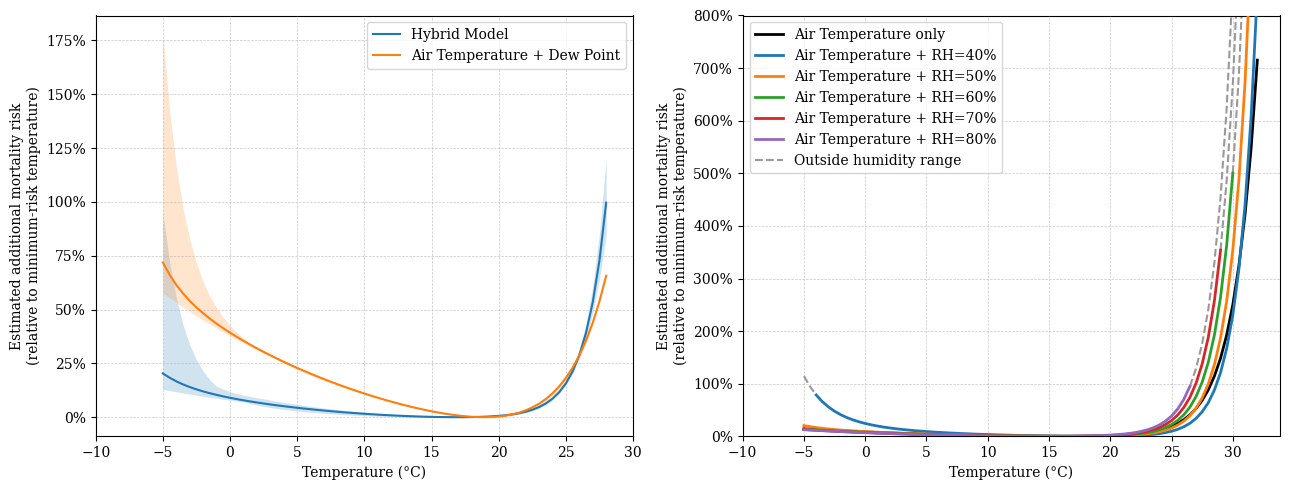

In [4]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np


# Reset then set serif font
mpl.rcdefaults()
mpl.rcParams['font.family'] = 'DejaVu Serif'

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax1, ax2 = axes

# ===== Left plot: Temperature–mortality curve =====
x = np.arange(-5, 28.5, 0.5)
for k, label in zip(setup, ['Hybrid Model', 'Air Temperature + Dew Point']):
    # Central line: unchanged
    y = (risk[k].mean(0) / risk[k].mean(0).min() - 1) * 100

    # Range: normalize each curve first, then take min/max over first dimension
    r = (risk[k] / risk[k].min(dim=1, keepdims=True).values - 1) * 100
    lo = r.min(axis=0).values
    hi = r.max(axis=0).values

    line, = ax1.plot(
        x,
        y,
        label=label,
        linewidth=1.5
    )

    ax1.fill_between(
        x,
        lo,
        hi,
        alpha=0.2,
        color=line.get_color(),
        linewidth=0
    )

ax1.set_xlabel('Temperature (°C)')
ax1.set_ylabel('Estimated additional mortality risk\n(relative to minimum-risk temperature)')
# ax1.set_title('Temperature–Mortality Relationship', weight='bold')
ax1.legend(loc='best')
ax1.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax1.set_xticks(np.arange(-10, 35, 5))

# ===== Right plot: Bar comparison =====
humidity_temp_map = {
    30: (1.9, 31.6),
    40: (-4.0, 32.5),
    50: (-7.8, 31.7),
    60: (-11.7, 30.2),
    70: (-13.0, 29.0),
    80: (-14.2, 26.6),
    90: (-14.3, 23.8),
    100: (-12.4, 21.3),
}

x = np.arange(-5, 32.5, 0.5)

# Reference: air temperature only
y_ref = (risk_1.mean(0) / risk_1.mean(0).min() - 1) * 100
ax2.plot(
    x,
    y_ref,
    label='Air Temperature only',
    linewidth=2,
    color='black'
 )

# Humidity-specific curves: solid in valid range, dashed grey outside
for h in sorted(risk_2.keys()):
    rh = h * 10
    y = (risk_2[h].mean(0) / risk_2[h].mean(0).min() - 1) * 100
    t_min, t_max = humidity_temp_map.get(rh, (x.min(), x.max()))

    mask_in = (x >= t_min) & (x <= t_max)
    mask_left = x < t_min
    mask_right = x > t_max

    idx_in = np.where(mask_in)[0]
    if idx_in.size == 0:
        continue

    # Plot valid interval in normal color
    ax2.plot(
        x[idx_in],
        y[idx_in],
        label=f'Air Temperature + RH={rh}%',
        linewidth=2,
        zorder=3
    )

    # Plot out-of-range intervals in grey dashed style and bridge with boundary points
    if np.any(mask_left):
        idx_left = np.where(mask_left)[0]
        idx_left_bridge = np.concatenate([idx_left, [idx_in[0]]])
        ax2.plot(
            x[idx_left_bridge],
            y[idx_left_bridge],
            color='0.6',
            linestyle='--',
            linewidth=1.5,
            zorder=2
        )

    if np.any(mask_right):
        idx_right = np.where(mask_right)[0]
        idx_right_bridge = np.concatenate([[idx_in[-1]], idx_right])
        ax2.plot(
            x[idx_right_bridge],
            y[idx_right_bridge],
            color='0.6',
            linestyle='--',
            linewidth=1.5,
            zorder=2
        )

# Add one legend entry for dashed grey segments
ax2.plot([], [], color='0.6', linestyle='--', linewidth=1.5, label='Outside humidity range')

ax2.set_xlabel('Temperature (°C)')
ax2.set_ylabel('Estimated additional mortality risk\n(relative to minimum-risk temperature)')
ax2.set_ylim(0, 800)

ax2.legend(loc='best')
ax2.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax2.set_xticks(np.arange(-10, 35, 5))

from matplotlib.ticker import FuncFormatter
percent_fmt = FuncFormatter(lambda y, _: f'{y:.0f}%')

ax1.yaxis.set_major_formatter(percent_fmt)
ax2.yaxis.set_major_formatter(percent_fmt)

# ===== Layout =====
plt.tight_layout()
# plt.savefig('combined_plots.png', dpi=300, bbox_inches='tight')
plt.show()

## Thresholds and humidity effects reported in the manuscript

In [5]:
# Use the same left-panel hybrid curve as Figure 2 at 50% relative humidity.
x = temperatures[comparison_points]
curve = risk["default"].mean(dim=0).numpy()
excess = (curve / curve.min() - 1) * 100
minimum = int(excess.argmin())

def crossing(xs, ys):
    above = np.flatnonzero(ys >= 1)
    if not len(above):
        return float("nan")
    i = above[0]
    return np.interp(1, ys[i - 1:i + 1], xs[i - 1:i + 1])

display(pd.Series({
    "Fitted minimum (°C)": x[minimum],
    "Cold crossing at +1% risk (°C)": crossing(x[:minimum + 1][::-1], excess[:minimum + 1][::-1]),
    "Heat crossing at +1% risk (°C)": crossing(x[minimum:], excess[minimum:]),
}))

temperature_index = int(np.flatnonzero(temperatures == 25)[0])
series = {"Air temperature only": risk_1,
          **{f"{humidity * 10}% RH": values for humidity, values in sorted(risk_2.items())}}
rows = []
for name, values in series.items():
    average = values.mean(dim=0)
    point = (average[temperature_index] / average.min() - 1) * 100
    members_at_25 = (values[:, temperature_index] / values.amin(dim=1) - 1) * 100
    rows.append((name, point.item(), members_at_25.min().item(), members_at_25.max().item()))
display(pd.DataFrame(rows, columns=["Setup", "Risk increase at 25 °C (%)",
                                   "Member minimum (%)", "Member maximum (%)"]).round(2))

Fitted minimum (°C)               17.000000
Cold crossing at +1% risk (°C)    11.560128
Heat crossing at +1% risk (°C)    20.617440
dtype: float64

,Setup,Risk increase at 25 °C (%),Member minimum (%),Member maximum (%)
0,Air temperature only,18.95,18.55,19.20
1,40% RH,9.62,8.30,12.81
2,50% RH,15.71,14.84,16.91
3,60% RH,22.39,20.42,23.33
4,70% RH,30.01,25.51,33.26
5,80% RH,38.52,31.62,44.87
